# 6. Model Soup, Explainability and Deployment Report

**Context**: The model comparison notebook selected the **top 2 models** from  
ConvNeXt-Tiny, EfficientNet-B0, and EfficientFormerV2-S0.  
The LOCO-CV notebook fine-tuned them on African data with Leave-One-Country-Out validation.

**This notebook** takes the best LOCO-trained checkpoints and delivers:

1. Per-domain performance report (Fetal DB test + each African country)
2. Confusion matrices & per-class metrics
3. Grad-CAM visualisations for each fetal plane class
4. Side-by-side Grad-CAM comparison between the two selected models
5. FPS benchmark & model weight summary
6. Deployment readiness scorecard

**Classes**: brain - femur - abdomen (3 standard planes, `other` excluded)
We focus on EfficientNetb0 and EfficientFormerV2

---
## 1 - Environment Setup

In [ ]:
# Environment setup: make modelling/ the working directory.
# Works when launched from the repo root, from modelling/, from modelling/notebooks/,
# or on Kaggle/Colab (where the public repository is cloned first).
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/PaulOkwija/US_standard_plane_classification.git"

if Path("src").is_dir() and Path("configs").is_dir():
    pass                                   # already in modelling/
elif Path("../src").is_dir():
    os.chdir("..")                         # modelling/notebooks/
elif Path("modelling/src").is_dir():
    os.chdir("modelling")                  # repo root
else:
    repo_dir = Path("US_standard_plane_classification")
    if not repo_dir.exists():
        subprocess.run(["git", "clone", REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir / "modelling")

sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

In [ ]:
# Download datasets & weights
!bash scripts/download_data.sh
!bash scripts/download_weights.sh

In [20]:
import torch
import yaml
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path
from PIL import Image

from src.models import build_model, benchmark_fps, count_parameters
from src.data import (
    FetalDataset, AfricanDataset, build_dataloaders,
    build_transforms, build_preprocessing_pipeline, CLASSES
)
from src.evaluation import evaluate_on_domain
from src.explainability import GradCAM, visualise_predictions
from src.utils import set_seed

set_seed(42)
sns.set_style("whitegrid")
device = "cuda" if torch.cuda.is_available() else "cpu"

with open("configs/base_config.yaml") as f:
    cfg = yaml.safe_load(f)

image_size  = cfg["data"]["image_size"]
fetal_dir   = Path(cfg["data"]["fetal_db_dir"])
african_dir = Path(cfg["data"]["african_dir"])
os.makedirs("docs", exist_ok=True)

# 3 classes
COMPARE_CLASSES = ["brain", "femur", "abdomen"]
NUM_CLASSES     = len(COMPARE_CLASSES)

# -- African data uses train/val/test splits --
# test = Malawi (held-out), train/val = other countries
AFRICAN_SPLITS = {
    "train": african_dir / "train",
    "val":   african_dir / "val",
    "test":  african_dir / "test",   # <- Malawi
}

print(f"Device         : {device}")
print(f"Classes        : {COMPARE_CLASSES}")
print(f"Fetal DB dir   : {fetal_dir}")
print(f"African dir    : {african_dir}")
print(f"African splits :")
for split, p in AFRICAN_SPLITS.items():
    exists = 'Pass' if p.exists() else 'Fail'
    print(f"  {split:6s} {exists} {p}")

Device         : cuda
Classes        : ['brain', 'femur', 'abdomen']
Fetal DB dir   : data/fetal_db
African dir    : data/african
African splits :
  train  [ok] data/african/train
  val    [ok] data/african/val
  test   [ok] data/african/test


---
## 2 - Combine LOCO Fold Weights (Model Soup)

Each LOCO-CV fold produced a checkpoint trained with one country held out as validation.  
We **average the state_dicts** across all 4 folds to produce a single consolidated model.  

Why this works:
- Each fold saw slightly different training data -> learned complementary features  
- Averaging smooths out fold-specific overfitting  
- No additional training or GPU time required  
- Well-established in the model soups literature (Wortsman et al., 2022)

In [21]:
def average_checkpoints(ckpt_paths, device="cpu"):
    """Average state_dicts from multiple checkpoints into one.
    
    Args:
        ckpt_paths: list of paths to .pt checkpoint files
        device: device for loading
    
    Returns:
        averaged state_dict
    """
    state_dicts = []
    for p in ckpt_paths:
        ckpt = torch.load(p, map_location=device)
        sd = ckpt.get("model_state_dict", ckpt)  # handle wrapped or bare
        state_dicts.append(sd)
        print(f"  Loaded: {Path(p).name}")
    
    # Average all parameters
    avg_sd = {}
    keys = state_dicts[0].keys()
    n = len(state_dicts)
    
    for key in keys:
        tensors = [sd[key].float() for sd in state_dicts]
        avg_sd[key] = sum(tensors) / n
        # Preserve original dtype (e.g. BatchNorm running stats)
        avg_sd[key] = avg_sd[key].to(state_dicts[0][key].dtype)
    
    print(f"\n  Averaged {len(keys)} parameter tensors across {n} folds.")
    return avg_sd

In [11]:
LOCO_FOLDS = {
    "efficientnet_b0": {
        "arch": "efficientnet_b0",
        "label": "EfficientNet-B0",
        "fold_ckpts": sorted(Path("checkpoints").glob("effb0_best_*.pt"))
                     if Path("checkpoints").exists()
                     else [],
    },
    "efficientformerv2_s0": {
        "arch": "efficientformerv2_s0",
        "label": "EfficientFormerV2-S0",
        "fold_ckpts": sorted(Path("checkpoints").glob("eff_former_best_*.pt"))
                     if Path("checkpoints").exists()
                     else [],
    },
}

# Show what was found
for key, info in LOCO_FOLDS.items():
    n = len(info["fold_ckpts"])
    print(f"{info['label']}: found {n} fold checkpoint(s)")
    for p in info["fold_ckpts"]:
        print(f"  {p}")
    if n == 0:
        print("   No fold checkpoints found - update the glob pattern above.")

EfficientNet-B0: found 4 fold checkpoint(s)
  checkpoints/effb0_best_f0.pt
  checkpoints/effb0_best_f1.pt
  checkpoints/effb0_best_f2.pt
  checkpoints/effb0_best_f3.pt
EfficientFormerV2-S0: found 4 fold checkpoint(s)
  checkpoints/eff_former_best_f0.pt
  checkpoints/eff_former_best_f1.pt
  checkpoints/eff_former_best_f2.pt
  checkpoints/eff_former_best_f3.pt


In [12]:
# Average fold weights and save consolidated checkpoints
os.makedirs("checkpoints/averaged", exist_ok=True)

averaged_ckpt_paths = {}

for key, info in LOCO_FOLDS.items():
    if len(info["fold_ckpts"]) < 2:
        print(f"\n[SKIP] {info['label']} - need at least 2 folds to average "
              f"(found {len(info['fold_ckpts'])})")
        continue

    print(f"\nAveraging {info['label']} ({len(info['fold_ckpts'])} folds) ...")
    avg_sd = average_checkpoints(info["fold_ckpts"])

    # Quick sanity check - load into model and verify it works
    test_model = build_model(info["arch"], num_classes=NUM_CLASSES, pretrained=False)
    test_model.load_state_dict(avg_sd, strict=False)
    print(f" State dict loads cleanly into {info['arch']}")

    # Save
    out_path = Path(f"checkpoints/averaged/{key}_loco_averaged.pt")
    torch.save({"model_state_dict": avg_sd}, out_path)
    averaged_ckpt_paths[key] = str(out_path)
    sz_mb = out_path.stat().st_size / 1e6
    print(f"  Saved: {out_path}  ({sz_mb:.1f} MB)")
    del test_model

print(f"\nConsolidated checkpoints: {averaged_ckpt_paths}")


Averaging EfficientNet-B0 (4 folds) ...
  Loaded: effb0_best_f0.pt
  Loaded: effb0_best_f1.pt
  Loaded: effb0_best_f2.pt
  Loaded: effb0_best_f3.pt

  Averaged 360 parameter tensors across 4 folds.
  [ok] State dict loads cleanly into efficientnet_b0
  Saved: checkpoints/averaged/efficientnet_b0_loco_averaged.pt  (16.3 MB)

Averaging EfficientFormerV2-S0 (4 folds) ...
  Loaded: eff_former_best_f0.pt
  Loaded: eff_former_best_f1.pt
  Loaded: eff_former_best_f2.pt
  Loaded: eff_former_best_f3.pt

  Averaged 568 parameter tensors across 4 folds.
  [ok] State dict loads cleanly into efficientformerv2_s0
  Saved: checkpoints/averaged/efficientformerv2_s0_loco_averaged.pt  (13.4 MB)

Consolidated checkpoints: {'efficientnet_b0': 'checkpoints/averaged/efficientnet_b0_loco_averaged.pt', 'efficientformerv2_s0': 'checkpoints/averaged/efficientformerv2_s0_loco_averaged.pt'}


---
## 3 - Load the Two Selected Models

These are the top-2 models from the comparison notebook, fine-tuned via LOCO-CV.  
Update the checkpoint paths below to match your LOCO output.

In [13]:
SELECTED_MODELS = {
    "efficientnet_b0": {
        "arch":  "efficientnet_b0",
        "ckpt":  averaged_ckpt_paths.get(
                     "efficientnet_b0",
                     "checkpoints/efficientnetb0_base_3c.pt",  # fallback
                 ),
        "label": "EfficientNet-B0",
    },
    "efficientformerv2_s0": {
        "arch":  "efficientformerv2_s0",
        "ckpt":  averaged_ckpt_paths.get(
                     "efficientformerv2_s0",
                     "checkpoints/efficientformerV2_base_3c.pt",  # fallback
                 ),
        "label": "EfficientFormerV2-S0",
    },
}

# Show which checkpoints we're using
for k, v in SELECTED_MODELS.items():
    source = "LOCO-averaged" if "averaged" in str(v['ckpt']) else "base (fallback)"
    print(f"{v['label']:30s} -> {v['ckpt']}  [{source}]")


EfficientNet-B0                -> checkpoints/averaged/efficientnet_b0_loco_averaged.pt  [LOCO-averaged]
EfficientFormerV2-S0           -> checkpoints/averaged/efficientformerv2_s0_loco_averaged.pt  [LOCO-averaged]


In [14]:
loaded_models = {}

for key, info in SELECTED_MODELS.items():
    ckpt_path = Path(info["ckpt"])
    if not ckpt_path.exists():
        print(f"[SKIP] {info['label']} - checkpoint not found at {ckpt_path}")
        continue

    ckpt = torch.load(ckpt_path, map_location="cpu")
    sd   = ckpt.get("model_state_dict", ckpt)  # handle bare state_dict or wrapped

    model = build_model(info["arch"], num_classes=NUM_CLASSES, pretrained=False)
    model.load_state_dict(sd, strict=False)
    model = model.to(device).eval()

    params = count_parameters(model)
    loaded_models[key] = {
        "model":  model,
        "label":  info["label"],
        "arch":   info["arch"],
        "params_M": round(params["total"] / 1e6, 2),
    }
    print(f" {info['label']:30s}  params={params['total']/1e6:.1f}M")

assert len(loaded_models) >= 1, "At least one model must load successfully."
print(f"\nLoaded {len(loaded_models)} model(s) for analysis.")

[ok] EfficientNet-B0                 params=4.0M
[ok] EfficientFormerV2-S0            params=3.2M

Loaded 2 model(s) for analysis.


---
## 4 - Per-Domain Performance Report

Evaluate each selected model on the Fetal DB test split and on each African country  
(with Malawi as the held-out LOCO test set).

In [22]:
preprocessing = build_preprocessing_pipeline(use_clahe=True)
val_tf = build_transforms(image_size, split="val")

# Build domain loaders
domain_loaders = {}

# Fetal DB test (3 classes only)
try:
    ds_fetal = FetalDataset(
        root_dir=str(fetal_dir / "test"),
        transform=val_tf,
        preprocessing=preprocessing,
    )
    domain_loaders["Fetal DB (test)"] = build_dataloaders(
        ds_fetal, ds_fetal, batch_size=32
    )["val"]
except Exception as e:
    print(f"Fetal DB test: {e}")

# African splits: train, val, test (Malawi)
split_labels = {
    "train": "African (train)",
    "val":   "African (val)",
    "test":  "Malawi (test)",
}

for split, split_dir in AFRICAN_SPLITS.items():
    if not split_dir.exists():
        print(f"{split}: directory not found at {split_dir}")
        continue
    try:
        ds_af = AfricanDataset(
            root_dir=str(split_dir),
            transform=val_tf,
            preprocessing=preprocessing,
        )
        label = split_labels.get(split, split)
        domain_loaders[label] = build_dataloaders(
            ds_af, ds_af, batch_size=16
        )["val"]
    except Exception as e:
        print(f"{split}: {e}")

print(f"\nBuilt loaders for {len(domain_loaders)} domains: {list(domain_loaders.keys())}")



Built loaders for 4 domains: ['Fetal DB (test)', 'African (train)', 'African (val)', 'Malawi (test)']


In [16]:
all_domain_results = {}

for model_key, minfo in loaded_models.items():
    print(f"\nEvaluating {minfo['label']} across all domains ...")
    model_results = {}
    for domain, loader in domain_loaders.items():
        try:
            metrics = evaluate_on_domain(
                minfo["model"], loader,
                device=device, class_names=COMPARE_CLASSES
            )
            model_results[domain] = metrics
            pr = metrics.get("pr_auc", metrics.get("pr_auc_macro", 0))
            f1 = metrics.get("f1", metrics.get("f1_macro", 0))
            print(f"  {domain:25s}  PR-AUC={pr:.4f}  F1={f1:.4f}")
        except Exception as e:
            print(f"  {domain:25s}  ERROR: {e}")
    all_domain_results[model_key] = model_results

print("\nDone.")


Evaluating EfficientNet-B0 across all domains ...
  Fetal DB (test)            PR-AUC=0.9969  F1=0.9880
  Test                       PR-AUC=0.9995  F1=0.9867
  Train                      PR-AUC=0.9993  F1=0.9855
  Val                        PR-AUC=0.9950  F1=0.9679

Evaluating EfficientFormerV2-S0 across all domains ...
  Fetal DB (test)            PR-AUC=0.9959  F1=0.9949
  Test                       PR-AUC=0.9985  F1=0.9867
  Train                      PR-AUC=0.9994  F1=0.9903
  Val                        PR-AUC=0.9950  F1=0.9566

Done.


In [17]:
# -- Build summary table --
rows = []
for model_key, minfo in loaded_models.items():
    for domain, m in all_domain_results.get(model_key, {}).items():
        rows.append({
            "Model":     minfo["label"],
            "Domain":    domain,
            "PR-AUC":    round(m.get("pr_auc", m.get("pr_auc_macro", 0)), 4),
            "F1":        round(m.get("f1", m.get("f1_macro", 0)), 4),
            "Accuracy":  round(m.get("accuracy", m.get("acc", 0)), 4),
            "Precision": round(m.get("precision_macro", m.get("precision", 0)), 4),
            "Recall":    round(m.get("recall_macro", m.get("recall", 0)), 4),
        })

df_domain = pd.DataFrame(rows)
df_domain.to_csv("docs/final_domain_performance.csv", index=False)
print(df_domain.to_string(index=False))

               Model          Domain  PR-AUC     F1  Accuracy  Precision  Recall
     EfficientNet-B0 Fetal DB (test)  0.9969 0.9880    0.9915     0.9830  0.9934
     EfficientNet-B0            Test  0.9995 0.9867    0.9867     0.9872  0.9867
     EfficientNet-B0           Train  0.9993 0.9855    0.9855     0.9856  0.9855
     EfficientNet-B0             Val  0.9950 0.9679    0.9677     0.9684  0.9677
EfficientFormerV2-S0 Fetal DB (test)  0.9959 0.9949    0.9966     0.9943  0.9956
EfficientFormerV2-S0            Test  0.9985 0.9867    0.9867     0.9872  0.9867
EfficientFormerV2-S0           Train  0.9994 0.9903    0.9903     0.9904  0.9903
EfficientFormerV2-S0             Val  0.9950 0.9566    0.9570     0.9573  0.9570


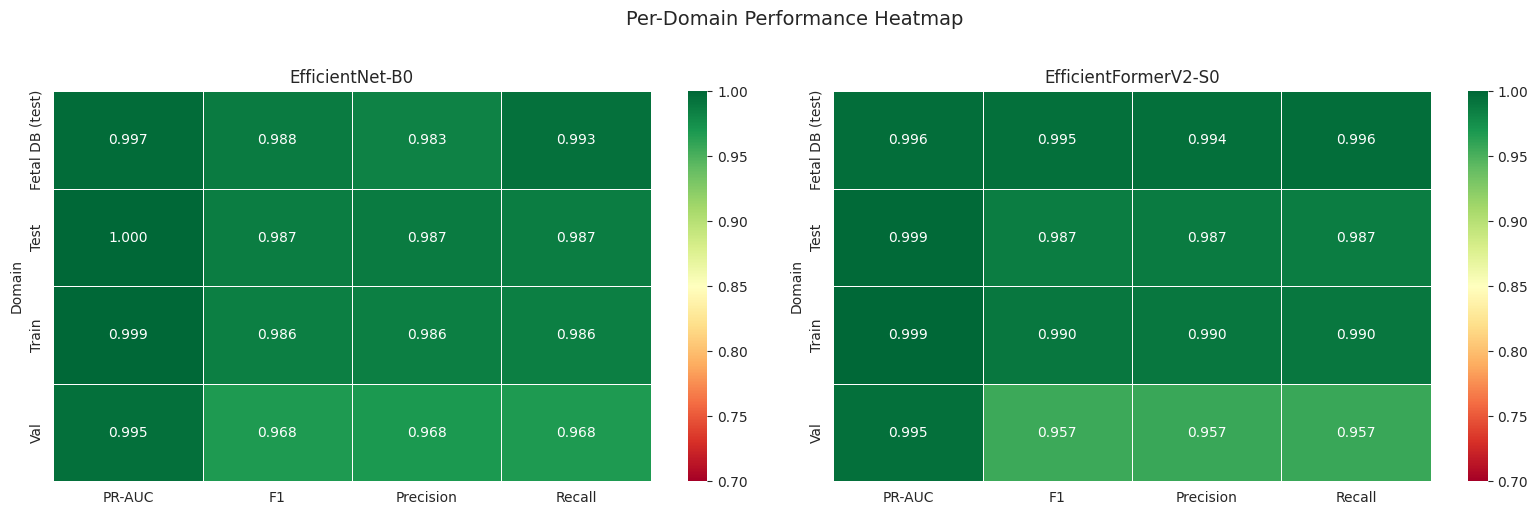

In [18]:
heat_metrics = ["PR-AUC", "F1", "Precision", "Recall"]

n_models = len(loaded_models)
fig, axes = plt.subplots(1, n_models, figsize=(8 * n_models, 5))
if n_models == 1:
    axes = [axes]

for ax, (model_key, minfo) in zip(axes, loaded_models.items()):
    df_m = df_domain[df_domain["Model"] == minfo["label"]].set_index("Domain")
    df_heat = df_m[[c for c in heat_metrics if c in df_m.columns]]
    sns.heatmap(df_heat, annot=True, fmt=".3f", cmap="RdYlGn",
                vmin=0.7, vmax=1.0, ax=ax, linewidths=0.5)
    ax.set_title(minfo["label"], fontsize=12)

plt.suptitle("Per-Domain Performance Heatmap", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("docs/domain_performance_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 5 - Confusion Matrices (Malawi Test Set)


EfficientNet-B0 - Classification Report (Malawi):
              precision    recall  f1-score   support

       brain     0.9993    0.9898    0.9945      1472
       femur     1.0000    0.9905    0.9952       524
     abdomen     0.9496    1.0000    0.9741       358

    accuracy                         0.9915      2354
   macro avg     0.9830    0.9934    0.9880      2354
weighted avg     0.9919    0.9915    0.9916      2354


EfficientFormerV2-S0 - Classification Report (Malawi):
              precision    recall  f1-score   support

       brain     0.9986    0.9980    0.9983      1472
       femur     0.9981    0.9943    0.9962       524
     abdomen     0.9861    0.9944    0.9903       358

    accuracy                         0.9966      2354
   macro avg     0.9943    0.9956    0.9949      2354
weighted avg     0.9966    0.9966    0.9966      2354



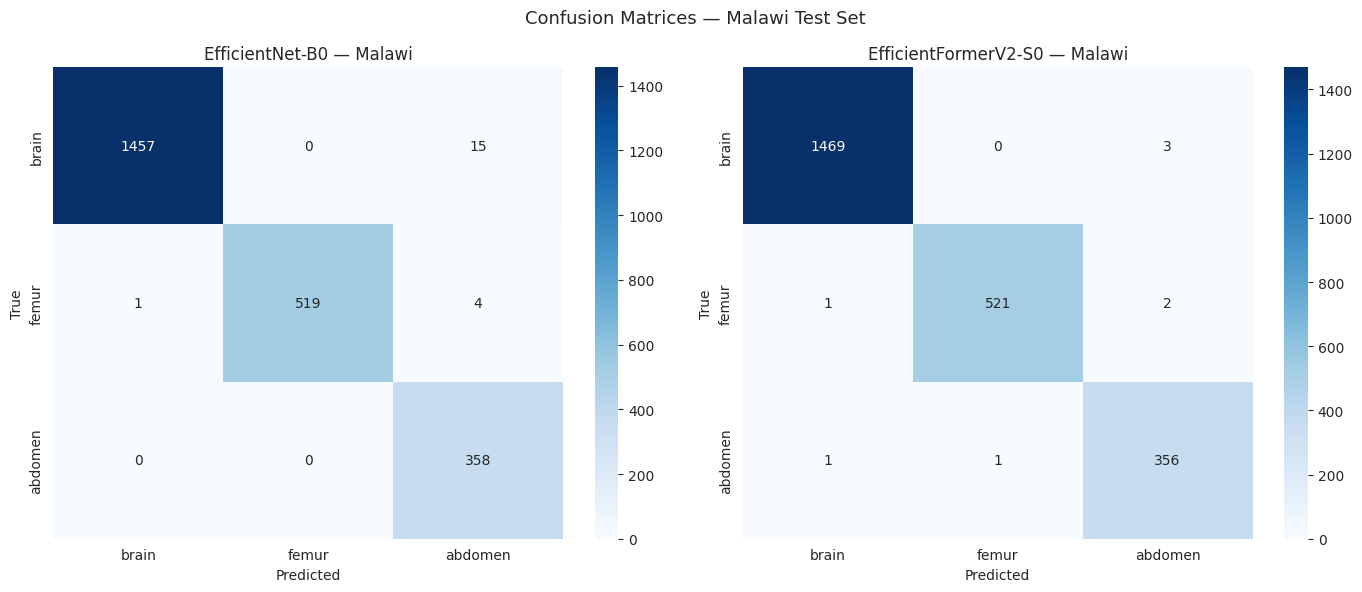

In [23]:
from sklearn.metrics import confusion_matrix, classification_report

malawi_key = [k for k in domain_loaders if "malawi" in k.lower() or "test" in k.lower()]
if malawi_key:
    malawi_loader = domain_loaders[malawi_key[0]]

    fig, axes = plt.subplots(1, len(loaded_models), figsize=(7 * len(loaded_models), 6))
    if len(loaded_models) == 1:
        axes = [axes]

    for ax, (model_key, minfo) in zip(axes, loaded_models.items()):
        model = minfo["model"]
        all_preds, all_labels = [], []

        with torch.no_grad():
            for batch in malawi_loader:
                images = batch[0].to(device) if isinstance(batch, (list, tuple)) else batch["image"].to(device)
                labels = batch[1] if isinstance(batch, (list, tuple)) else batch["label"]
                logits = model(images)
                preds  = logits.argmax(dim=1).cpu()
                all_preds.append(preds)
                all_labels.append(labels)

        all_preds  = torch.cat(all_preds).numpy()
        all_labels = torch.cat(all_labels).numpy()

        cm = confusion_matrix(all_labels, all_preds)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                    xticklabels=COMPARE_CLASSES, yticklabels=COMPARE_CLASSES)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("True")
        ax.set_title(f"{minfo['label']} - Malawi")

        print(f"\n{minfo['label']} - Classification Report (Malawi):")
        print(classification_report(all_labels, all_preds,
                                     target_names=COMPARE_CLASSES, digits=4))

    plt.suptitle("Confusion Matrices - Malawi Test Set", fontsize=13)
    plt.tight_layout()
    plt.savefig("docs/confusion_matrix_malawi.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Malawi loader not found - skipping confusion matrices.")

---
## 6 - Grad-CAM Visualisations

Shows where each model "looks" when classifying each fetal plane.  
Clinically meaningful Grad-CAMs should highlight anatomically relevant structures  
(e.g. skull for brain, long bone shaft for femur, abdominal circumference for abdomen).

In [39]:
def get_sample_images(classes, fetal_dir, african_dir, preprocessing, image_size, n=1):
    """Find one sample image per class, preferring African test (Malawi)."""
    samples = {}
    for cls in classes:
        search_dirs = [
            african_dir / "test" / cls,      # Malawi test
            fetal_dir / "test" / cls,         # Fetal DB test
            african_dir / "val" / cls,        # African val
        ]
        for d in search_dirs:
            if not d.exists():
                continue
            imgs = sorted(d.glob("*.png")) + sorted(d.glob("*.jpg"))
            if imgs:
                img_pil = Image.open(imgs[10]).convert("RGB")
                if preprocessing:
                    img_pil = preprocessing(img_pil)
                samples[cls] = img_pil
                print(f"  {cls}: {imgs[10]}")
                break
        if cls not in samples:
            print(f"  [WARN] No sample image found for class '{cls}'")
    return samples


sample_images = get_sample_images(
    COMPARE_CLASSES, fetal_dir, african_dir, preprocessing, image_size
)
print(f"\nSample images found for: {list(sample_images.keys())}")


  brain: data/african/test/brain/patient013_MWI_plane1.png
  femur: data/african/test/femur/patient013_MWI_plane2.png
  abdomen: data/african/test/abdomen/patient013_MWI_plane0.png

Sample images found for: ['brain', 'femur', 'abdomen']


In [40]:
# Find the correct Grad-CAM target layer per architecture
# EfficientFormerV2 is a hybrid transformer - its last conv-like block
# differs from standard CNNs. We auto-detect the best target layer.

def find_gradcam_target_layer(model, arch_name):
    """Find the best target layer for Grad-CAM based on architecture.
    
    Strategy: walk backwards through named modules and pick the last
    layer that produces spatial feature maps (Conv2d, BatchNorm2d after
    a conv, or the last stage/block in transformers).
    """
    # Try architecture-specific known layers first
    known_targets = {
        "efficientnet_b0":      ["conv_head", "bn2", "features.8", "features.7"],
        "efficientformerv2_s0": ["stages.3", "stages.3.blocks", "network.6", "network.5",
                                 "stages.2", "norm"],
        "convnext_tiny":        ["stages.3", "features.7", "norm_pre"],
    }
    
    candidates = known_targets.get(arch_name, [])
    named = dict(model.named_modules())
    
    for name in candidates:
        if name in named:
            print(f"  {arch_name}: using known target layer '{name}'")
            return named[name]
    
    # Fallback: find the last Conv2d or BatchNorm2d layer
    last_conv = None
    last_conv_name = None
    for name, module in model.named_modules():
        if isinstance(module, (torch.nn.Conv2d, torch.nn.BatchNorm2d)):
            last_conv = module
            last_conv_name = name
    
    if last_conv is not None:
        print(f"  {arch_name}: fallback to last conv/bn layer '{last_conv_name}'")
        return last_conv
    
    # Last resort: find any module with spatial output
    print(f"  {arch_name}: WARNING - could not find a good target layer")
    return None

for model_key, minfo in loaded_models.items():
    model = minfo["model"]
    print(f"\n{'='*50}")
    print(f"{minfo['label']} - last 15 named modules:")
    print(f"{'='*50}")
    modules = list(model.named_modules())
    for name, mod in modules[-15:]:
        print(f"  {name:50s}  {mod.__class__.__name__}")
    
    target = find_gradcam_target_layer(model, minfo["arch"])
    minfo["gradcam_target"] = target
    print()

# Fallback
import inspect

_gradcam_sig = inspect.signature(GradCAM.__init__)
_accepts_target_layer = "target_layer" in _gradcam_sig.parameters

if _accepts_target_layer:
    print("GradCAM natively accepts target_layer")
    def make_gradcam(model, target_layer=None):
        if target_layer is not None:
            return GradCAM(model, target_layer=target_layer)
        return GradCAM(model)
else:
    print("GradCAM does NOT accept target_layer - using hook-patching wrapper")
    def make_gradcam(model, target_layer=None):
        cam = GradCAM(model)
        if target_layer is not None:
            # Remove default hooks and re-register on the correct layer
            try:
                cam.remove_hooks()
            except Exception:
                pass
            cam.activations = None
            cam.gradients = None
            def fwd_hook(module, inp, out):
                cam.activations = out
            def bwd_hook(module, grad_in, grad_out):
                cam.gradients = grad_out[0]
            cam._fwd_handle = target_layer.register_forward_hook(fwd_hook)
            cam._bwd_handle = target_layer.register_full_backward_hook(bwd_hook)
            # Override remove_hooks to clean up our custom handles
            def _remove():
                cam._fwd_handle.remove()
                cam._bwd_handle.remove()
            cam.remove_hooks = _remove
        return cam



EfficientNet-B0 - last 15 named modules:
  blocks.6.0.se.conv_expand                           Conv2d
  blocks.6.0.se.gate                                  Sigmoid
  blocks.6.0.conv_pwl                                 Conv2d
  blocks.6.0.bn3                                      BatchNormAct2d
  blocks.6.0.bn3.drop                                 Identity
  blocks.6.0.bn3.act                                  Identity
  blocks.6.0.drop_path                                Identity
  conv_head                                           Conv2d
  bn2                                                 BatchNormAct2d
  bn2.drop                                            Identity
  bn2.act                                             SiLU
  global_pool                                         SelectAdaptivePool2d
  global_pool.pool                                    AdaptiveAvgPool2d
  global_pool.flatten                                 Flatten
  classifier                                          L

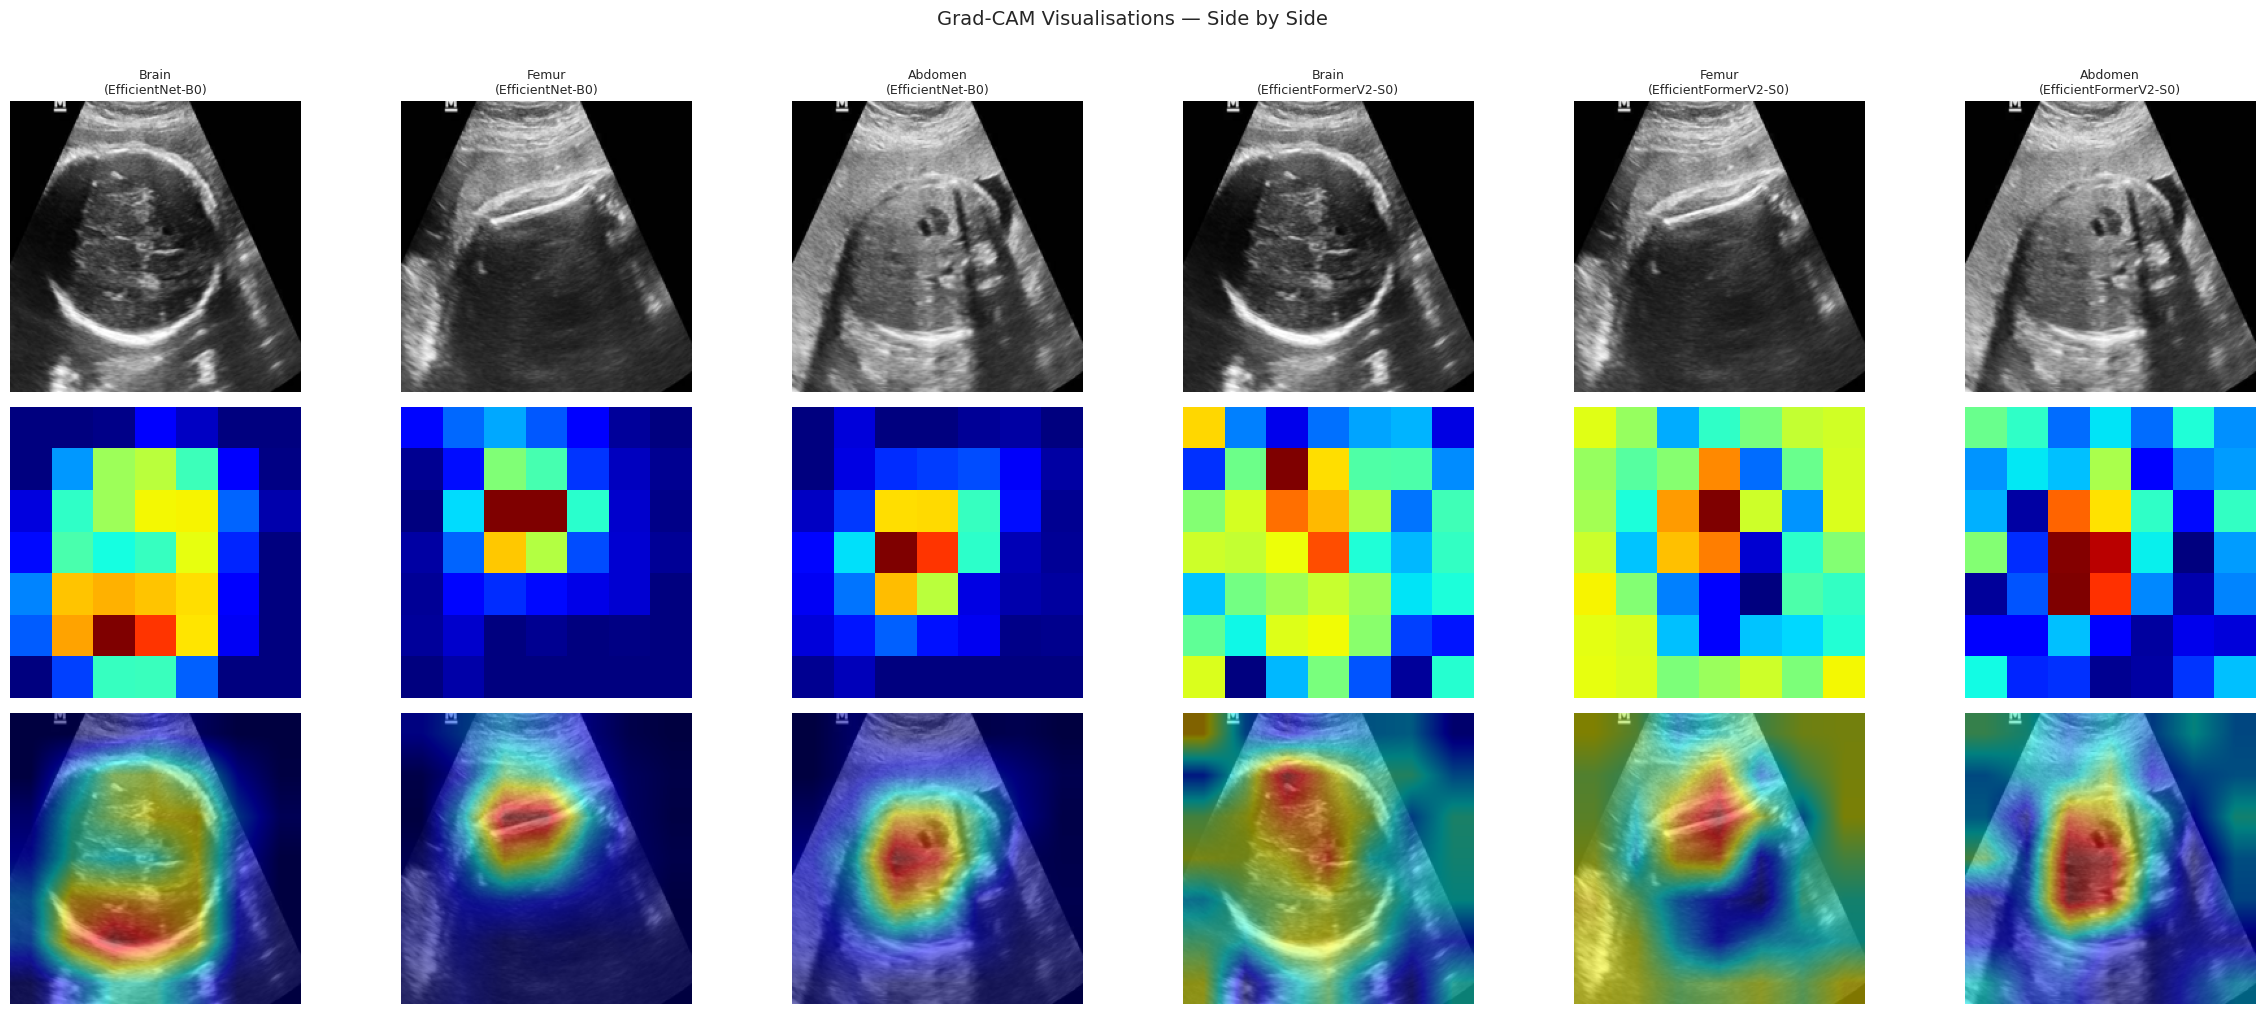

In [50]:
val_tf_vis = build_transforms(image_size, split="val")

n_models = len(loaded_models)
n_classes = len(sample_images)

fig, axes = plt.subplots(3, n_classes * n_models, figsize=(4 * n_classes * n_models, 10))
row_titles = ["Original", "Grad-CAM", "Overlay"]

col = 0
for model_key, minfo in loaded_models.items():
    cam_engine = make_gradcam(minfo["model"], target_layer=minfo.get("gradcam_target"))

    for cls in sample_images:
        img_pil = sample_images[cls]
        img_np  = np.array(img_pil.resize((image_size, image_size)))
        img_t   = val_tf_vis(img_pil)

        cam     = cam_engine(img_t.clone())
        cam_arr = np.array(cam) if not isinstance(cam, np.ndarray) else cam
        if cam_arr.max() - cam_arr.min() < 0.01:
            print(f" {minfo['label']} / {cls}: CAM near-flat (range={cam_arr.max()-cam_arr.min():.6f})")

        overlay = cam_engine.generate_overlay(img_np, cam)

        axes[0, col].imshow(img_np);           axes[0, col].axis("off")
        axes[1, col].imshow(cam, cmap="jet");  axes[1, col].axis("off")
        axes[2, col].imshow(overlay);          axes[2, col].axis("off")

        axes[0, col].set_title(f"{cls.title()}\n({minfo['label']})", fontsize=9)
        col += 1

    cam_engine.remove_hooks()

for r, label in enumerate(row_titles):
    axes[r, 0].set_ylabel(label, fontsize=11, rotation=90)

plt.suptitle("Grad-CAM Visualisations - Side by Side", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig("docs/gradcam_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 7 - FPS Benchmark & Weight Sizes

Real-time inference requires >= 15 FPS on the target hardware.  
We benchmark on the current device (GPU or CPU) and report checkpoint sizes.

In [42]:
fps_rows = []

for model_key, minfo in loaded_models.items():
    fps_info = benchmark_fps(
        minfo["model"], image_size=image_size, device=device,
        warmup_runs=10, eval_runs=100
    )

    # Checkpoint file size
    ckpt_path = Path(SELECTED_MODELS[model_key]["ckpt"])
    weight_mb = round(ckpt_path.stat().st_size / 1e6, 1) if ckpt_path.exists() else float("nan")

    fps_rows.append({
        "Model":       minfo["label"],
        "Params (M)":  minfo["params_M"],
        "Weight (MB)": weight_mb,
        "FPS":         round(fps_info["fps"], 1),
        "Latency (ms)": round(fps_info["latency_ms_mean"], 2),
        "Device":      device,
        ">=15 FPS":     "Pass" if fps_info["fps"] >= 15 else "Fail",
    })
    print(f"{minfo['label']:30s}  FPS={fps_info['fps']:.1f}  "
          f"Latency={fps_info['latency_ms_mean']:.1f}ms  Weight={weight_mb}MB")

df_fps = pd.DataFrame(fps_rows)
df_fps.to_csv("docs/deployment_fps_benchmark.csv", index=False)
df_fps

EfficientNet-B0                 FPS=131.4  Latency=7.6ms  Weight=16.3MB
EfficientFormerV2-S0            FPS=88.7  Latency=11.3ms  Weight=13.4MB


,Model,Params (M),Weight (MB),FPS,Latency (ms),Device,>=15 FPS
0,EfficientNet-B0,4.01,16.3,131.4,7.61,cuda,[ok]
1,EfficientFormerV2-S0,3.25,13.4,88.7,11.27,cuda,[ok]


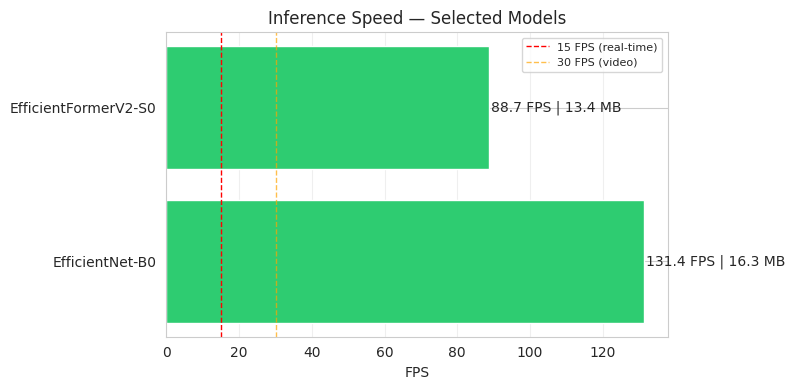

In [43]:
# -- FPS comparison bar chart --
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#2ecc71" if row[">=15 FPS"] == "[ok]" else "#e74c3c" for _, row in df_fps.iterrows()]
bars = ax.barh(df_fps["Model"], df_fps["FPS"], color=colors, edgecolor="white")

for bar, (_, row) in zip(bars, df_fps.iterrows()):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f"{row['FPS']} FPS | {row['Weight (MB)']} MB",
            va="center", fontsize=10)

ax.axvline(x=15, color="red",    ls="--", lw=1, label="15 FPS (real-time)")
ax.axvline(x=30, color="orange", ls="--", lw=1, label="30 FPS (video)", alpha=0.7)
ax.set_xlabel("FPS")
ax.set_title("Inference Speed - Selected Models")
ax.legend(fontsize=8)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("docs/fps_benchmark_final.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 8 - Deployment Readiness Scorecard

A single summary table combining accuracy, speed, and size for deployment decisions.

In [44]:
# Build the scorecard from collected data
scorecard_rows = []

for model_key, minfo in loaded_models.items():
    # Malawi metrics (the held-out test domain)
    malawi_metrics = all_domain_results.get(model_key, {}).get(
        malawi_key[0] if malawi_key else "Malawi (test)", {}
    )

    # FPS row
    fps_row = next((r for r in fps_rows if r["Model"] == minfo["label"]), {})

    scorecard_rows.append({
        "Model":              minfo["label"],
        "Params (M)":         minfo["params_M"],
        "Checkpoint (MB)":    fps_row.get("Weight (MB)", ""),
        "FPS":                fps_row.get("FPS", ""),
        "Latency (ms)":       fps_row.get("Latency (ms)", ""),
        "Real-time ready":    fps_row.get(">=15 FPS", ""),
        "Malawi PR-AUC":      round(malawi_metrics.get("pr_auc",
                                    malawi_metrics.get("pr_auc_macro", 0)), 4),
        "Malawi F1":          round(malawi_metrics.get("f1",
                                    malawi_metrics.get("f1_macro", 0)), 4),
        "Malawi Accuracy":    round(malawi_metrics.get("accuracy",
                                    malawi_metrics.get("acc", 0)), 4),
    })

df_scorecard = pd.DataFrame(scorecard_rows)
df_scorecard.to_csv("docs/deployment_scorecard.csv", index=False)

print("\n" + "="*70)
print("  DEPLOYMENT READINESS SCORECARD")
print("="*70)
print(df_scorecard.to_string(index=False))
print("="*70)


  DEPLOYMENT READINESS SCORECARD
               Model  Params (M)  Checkpoint (MB)   FPS  Latency (ms) Real-time ready  Malawi PR-AUC  Malawi F1  Malawi Accuracy
     EfficientNet-B0        4.01             16.3 131.4          7.61               [ok]         0.9969     0.9880           0.9915
EfficientFormerV2-S0        3.25             13.4  88.7         11.27               [ok]         0.9959     0.9949           0.9966


---
## 10 - Export All Artefacts

In [51]:
docs = Path("docs")
artefacts = sorted(docs.glob("*"))

print("Generated artefacts:")
for p in artefacts:
    size_kb = p.stat().st_size / 1024
    print(f"  {p.name:45s}  {size_kb:>7.1f} KB")

Generated artefacts:
  confusion_matrix_malawi.png                       70.9 KB
  deployment_fps_benchmark.csv                       0.2 KB
  deployment_scorecard.csv                           0.2 KB
  domain_performance_heatmap.png                    77.2 KB
  experiment_log.md                                  1.9 KB
  final_domain_performance.csv                       0.5 KB
  fps_benchmark_final.png                           42.3 KB
  gradcam_comparison.png                          1552.3 KB


In [53]:
# Zip and download artefacts
import shutil
from IPython.display import FileLink, display

zip_path = "explainability_artefacts"
shutil.make_archive(zip_path, "zip", "docs")

print(f"Packed: {zip_path}.zip ({Path(zip_path + '.zip').stat().st_size / 1e6:.1f} MB)")

# Clickable download link - must be relative to /kaggle/working/
display(FileLink("explainability_artefacts.zip", result_html_prefix=" Download: "))

Packed: /kaggle/working/explainability_artefacts.zip (1.7 MB)


/kaggle/working/US_standard_plane_classification/modelling/explainability_artefacts.zip